In [39]:
!pip install prettytable

Defaulting to user installation because normal site-packages is not writeable


## SU Meta Description
<p>
Discover the Heart Disease Prediction System, a machine learning model that analyzes patient clinical data to predict heart disease risk with accuracy and insights.
</p>

## Introduction

##### **Definition** 
    A binary classification ML task that predicts whether a patient has heart disease (1) or does not have heart disease (0) using clinical diagnostic attributes (e.g., chest pain type, max heart rate, ST depression, major vessels).
##### **Application** 
    It is mainly used for early clinical decision support, screening cardiovascular risk, and analyzing the impact of physiological factors on heart disease.

## Input and Output

### Inputs (Features / Attributes)

| **Input Feature/Attribute** | **Possible Values** |
| ------------ | ---------------------------------- |
| **cp** (Chest Pain Type) | 0: Typical Angina, 1: Atypical Angina, 2: Non-anginal Pain, 3: Asymptomatic |
| **thalach** (Max Heart Rate) | Continuous numerical value (e.g., 60 to 220 BPM) |
| **oldpeak** (ST Depression) | Continuous numerical value (e.g., 0.0 to 6.2) |
| **ca** (Major Vessels) | 0, 1, 2, 3, 4 (Number of major vessels colored by fluoroscopy) |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| -------------------- | ------------------------- |
| **Target** | Yes (Heart Disease Detected), No (No Heart Disease Detected) |

### Examples (Heart Disease Dataset)

| cp | thalach | oldpeak | ca | Target |
| :----: | :----: | :-----: | :----: | :------: |
| 0 | 150 | 2.3 | 0 | Yes |
| 2 | 168 | 1.0 | 0 | No |
| 1 | 153 | 0.8 | 0 | No |
| 0 | 108 | 1.5 | 1 | Yes |
| 0 | 122 | 1.0 | 0 | No |

##  Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Execute the Training Phase
  - Step 5.1: Splitting Sample Data into Training Data and Testing Data
  - Step 5.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 5.3: Train the Support Vector Classifier
  - Step 5.4: Save the Trained Model
- Step 6: Execute the Testing Phase
  - Step 6.1: Splitting Input Vectors and Outputs/Labels of Testing Data
  - Step 6.2: Load the Saved Model
  - Step 6.3: Evaluate the Machine Learning Model
    - Step 6.3.1: Make Predictions with the Trained Models on Testing Data
  - Step 6.4: Calculate the Accuracy Score
  - **Step 6.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) — NEW**
- Step 7: Execute the Application Phase
  - Step 7.1: Take Input from User
  - Step 7.2: Convert User Input into Feature Vector
  - Step 7.3: Label Encoding of Feature Vector
  - Step 7.4: Load the Saved Model
  - Step 7.5: Model Prediction
    - Step 7.5.1: Apply Model and Return Prediction to the User
- Step 8: Execute the Feedback Phase
  - Step 8.1: Collect Feedback from Users and Domain Experts
  - Step 8.2: Make a List of Potential Improvements
  - Step 8.3: Improve the Model Based on Feedback
- **Step 9: Deploy Your Model as a Public Web App (NEW)**
  - Step 9.1: Why Deploy a Model?
  - Step 9.2: Create a GitHub Account and Repository
  - Step 9.3: Write a Simple Web App
  - Step 9.4: Create a Streamlit Community Cloud Account
  - Step 9.5: Deploy Your App
  - Step 9.6: Troubleshooting Common Issues
  - Step 9.7: Share Your Live Link


## Code – Heart Disease Prediction Survival

###  Step 1: Import Libraries

In [40]:
"""
Purpose of this code:
----------------------
This script imports the required libraries for building and evaluating a
machine learning model. It sets up tools for data manipulation, preprocessing,
splitting datasets, training a Support Vector Machine (SVM) model,
evaluating accuracy, and displaying results in tabular form.
"""

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns


### Step 2: Load Sample Data

In [41]:
"""
Purpose of this section:
-------------------------
This part of the code loads a sample dataset from a CSV file into a
pandas DataFrame. It then displays the dataset so that students can
see the raw data being used for further processing and model training.
"""

# Read the CSV file and load it into a pandas DataFrame
# 'sample-data.csv' should be present in the working directory
sample_data = pd.read_csv("dataset.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)



Sample Data:

     cp  thalach  oldpeak  ca  target
0     3      150      2.3   0       1
1     2      187      3.5   0       1
2     1      172      1.4   0       1
3     1      178      0.8   0       1
4     0      163      0.6   0       1
5     0      148      0.4   0       1
6     1      153      1.3   0       1
7     1      173      0.0   0       1
8     2      162      0.5   0       1
9     2      174      1.6   0       1
10    0      160      1.2   0       1
11    2      139      0.2   0       1
12    1      171      0.6   0       1
13    3      144      1.8   0       1
14    3      162      1.0   0       1
15    2      158      1.6   0       1
16    2      172      0.0   0       1
17    3      114      2.6   0       1
18    0      171      1.5   0       1
19    3      151      1.8   2       1
20    0      161      0.5   0       1
21    2      179      0.4   0       1
22    0      178      0.0   0       1
23    2      137      1.0   0       1
24    3      178      1.4   0     

### Step 3: Understand and Pre-process Sample Data

####  Step 3.1: Understand Sample Data

In [42]:
"""
Purpose of this section:
-------------------------
This part of the code helps us understand the dataset by:
1. Printing the names of all attributes (columns) in the DataFrame.
2. Showing the total number of instances (rows) available in the dataset.
"""

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count using len() to get total row count
print("\n\nNumber of Instances in Sample Data:", len(sample_data))
print("========================================\n")



Attributes in Sample Data:

Index(['cp', 'thalach', 'oldpeak', 'ca', 'target'], dtype='object')


Number of Instances in Sample Data: 303



#### Step 3.2: Pre-process Sample Data
o   Sample Data is already Preprocessed
o   No Preprocessing needs to be Performed

#### Step 4: Feature Extraction
o   Features are already Extracted
o   No Feature Extraction needs to be Performed

In [43]:
# 1. Select the 4 chosen predictor features
X = sample_data[["cp", "thalach", "oldpeak", "ca"]]

# 2. Select the target variable
y = sample_data["target"]

### Step 5: Execute the Training Phase

#### Step 5.1: Splitting Sample Data into Training Data and Testing Data

In [93]:
"""
Purpose of this section:
-------------------------
This part of the code splits the Heart Disease dataset into Training Data and Testing Data.
- Training Data (80%) is used to train the machine learning model.
- Testing Data (20%) is used to evaluate model accuracy on unseen patient records.
"""

# Split dataset into training (80%) and testing (20%)
# shuffle=True and stratify ensure balanced target classes in both splits
training_data, testing_data = train_test_split(
    sample_data,
    test_size=0.2,
    random_state=0,
    shuffle=True,
    stratify=sample_data['target']
)

# Save the training and testing datasets to CSV files
training_data.to_csv('training_data.csv', index=False, header=True)
testing_data.to_csv('testing_data.csv', index=False, header=True)

# Display shapes of the resulting datasets
print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


### Step 5.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [94]:
"""
Purpose of this section:
-------------------------
This part of the code separates the predictor features (cp, thalach, oldpeak, ca)
and the target output label from the heart disease training dataset.
"""

# Extract input vectors (features: cp, thalach, oldpeak, ca) from training data
input_vector_train = training_data.drop(columns=["target"])

# Extract output labels (target) from training data
output_label_train = training_data["target"]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### 5.3: Train the Support Vector Classifier

In [95]:
"""
Purpose of this section:
-------------------------
This part of the code trains a Support Vector Classifier (SVC) on the heart disease training data.
The SVC finds the optimal hyperplane boundary to separate patients with heart disease (target=1) 
from patients without heart disease (target=0) based on cp, thalach, oldpeak, and ca.
"""

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier (using default gamma='scale' for optimal kernel scaling)
svc_model = svm.SVC(kernel='rbf', gamma='scale', random_state=0)

# Train the model using the heart disease feature vectors and target labels
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and configuration)
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(random_state=0)


### Step 5.4: Save the Trained Model

In [96]:
"""
Purpose of this section:
-------------------------
This part of the code saves the trained Support Vector Classifier (SVC) model
to a pickle file so it can be reloaded during the testing and application phases.
"""

# Define the file path for saving the trained model
model_filename = 'heart_disease_svc_model.pkl'

# Save the trained SVC model to a pickle file
with open(model_filename, 'wb') as file:
    pickle.dump(svc_model, file)

print(f"Model successfully saved as: {model_filename}")

Model successfully saved as: heart_disease_svc_model.pkl


### Step 6: Execute the Testing Phase

#### Step 6.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [97]:
"""
Purpose of this section:
-------------------------
This part of the code separates the predictor features (cp, thalach, oldpeak, ca)
and the target output label from the heart disease testing dataset.
"""

# Extract input vectors (features: cp, thalach, oldpeak, ca) from testing data
input_vector_test = testing_data.drop(columns=["target"])

# Extract output labels (target) from testing data
output_label_test = testing_data["target"]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 6.2: Load the Saved Model

In [98]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
heart disease model from disk into memory for testing and evaluation.
"""

# Define the model filename used during the save step
model_filename = 'heart_disease_svc_model.pkl'

# Load the saved SVC model from disk
with open(model_filename, 'rb') as file:
    model = pickle.load(file)

print(f"Model successfully loaded from: {model_filename}")

Model successfully loaded from: heart_disease_svc_model.pkl


### Step 6.3: Evaluate the Machine Learning Model

#### Step 6.3.1: Make Predictions with the Trained Models on Testing Data

In [99]:
"""
Purpose of this section:
-------------------------
This part of the code evaluates the trained Support Vector Classifier (SVC)
on the heart disease testing data, attaches predictions to the patient records,
and exports the output to a CSV file.
"""

# Make predictions using the test feature vectors (cp, thalach, oldpeak, ca)
model_predictions = model.predict(input_vector_test)

# Avoid chained assignment warnings when adding predictions to DataFrame
pd.options.mode.chained_assignment = None

# Attach predictions to testing data (copying to avoid SettingWithCopyWarning)
testing_data_results = testing_data.copy()
testing_data_results["Predictions"] = model_predictions

# Save testing data along with model predictions to CSV
testing_data_results.to_csv('model_predictions.csv', index=False, header=True)

print("\n\nPredictions Returned by Heart Disease SVC Model:")
print("================================================\n")
print(testing_data_results)



Predictions Returned by Heart Disease SVC Model:

     cp  thalach  oldpeak  ca  target  Predictions
24    3      178      1.4   0       1            1
67    1      175      0.6   0       1            1
13    3      144      1.8   0       1            1
112   2      133      0.2   0       1            0
80    2      179      0.0   0       1            1
32    1      188      0.0   0       1            1
40    2      142      1.5   1       1            1
77    1      164      0.0   0       1            1
4     0      163      0.6   0       1            1
96    0      157      1.2   0       1            1
177   2      158      0.0   0       0            1
298   0      123      0.2   0       0            0
246   0      150      1.9   2       0            1
204   0      145      6.2   3       0            1
95    0      111      0.0   0       1            0
232   0      145      0.8   1       0            1
2     1      172      1.4   0       1            1
186   0      144      1.4   1 

### Step 7.4: Calculate the Accuracy Score

In [100]:
"""
Purpose of this section:
-------------------------
This part of the code calculates how accurate the trained model is on the
heart disease testing dataset by comparing true target values against predictions.
"""

# Calculate accuracy score using true 'target' labels and model 'Predictions'
model_accuracy_score = accuracy_score(
    testing_data_results["target"],
    testing_data_results["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(f"{round(model_accuracy_score * 100, 2)}%")



Accuracy Score:

73.77%


### Step 6.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.83      0.54      0.65        28
   Heart Disease (1)       0.70      0.91      0.79        33

            accuracy                           0.74        61
           macro avg       0.77      0.72      0.72        61
        weighted avg       0.76      0.74      0.73        61


Confusion Matrix:

                          Predicted: No Heart Disease  \
Actual: No Heart Disease                           15   
Actual: Heart Disease                               3   

                          Predicted: Heart Disease  
Actual: No Heart Disease                        13  
Actual: Heart Disease                           30  


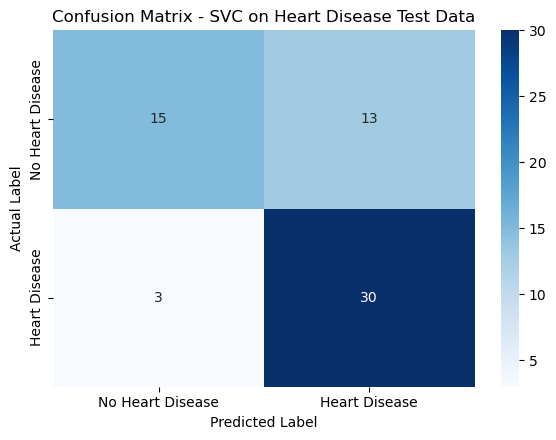

In [101]:
"""
Purpose of this section:
-------------------------
Accuracy alone can be misleading, especially on small or imbalanced medical datasets.
This section evaluates standard classification metrics for Heart Disease prediction:
- Precision: Of everyone predicted to have heart disease, how many actually have it?
- Recall (Sensitivity): Of everyone who actually has heart disease, how many did the model correctly identify?
- F1-score: The harmonic mean of precision and recall.
- Confusion Matrix: A tabular view showing true vs. false positives/negatives.
"""

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    testing_data_results["target"],
    testing_data_results["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"]
))

conf_matrix = confusion_matrix(
    testing_data_results["target"], 
    testing_data_results["Predictions"]
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No Heart Disease", "Actual: Heart Disease"],
    columns=["Predicted: No Heart Disease", "Predicted: Heart Disease"]
)

print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

# Plot confusion matrix heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    conf_matrix, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['No Heart Disease', 'Heart Disease'],
    yticklabels=['No Heart Disease', 'Heart Disease']
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - SVC on Heart Disease Test Data')
plt.tight_layout()
plt.show()

### Step 7: Execute the Application Phase

#### Step 7.1: Take Input from User

In [103]:
"""
Purpose of this section:
-------------------------
This part of the code allows the user to enter patient clinical data
(Chest Pain Type, Maximum Heart Rate, ST Depression, Major Vessels).
In an interactive Jupyter session, running this cell will prompt you for input().
For this notebook copy, we pre-fill sample patient values so the notebook can also be read/run
top-to-bottom without needing to type anything.

To try your own values interactively, replace the four lines below with:
    cp_input = input("Please enter Chest Pain Type (0: Typical, 1: Atypical, 2: Non-anginal, 3: Asymptomatic): ").strip()
    thalach_input = input("Please enter Maximum Heart Rate Achieved (e.g., 150): ").strip()
    oldpeak_input = input("Please enter ST Depression value (e.g., 1.5): ").strip()
    ca_input = input("Please enter Number of Major Vessels (0-4): ").strip()
"""

# Demo patient (edit these values, or swap in input() calls as shown above)
cp_input = 2       # Non-anginal pain (0 to 3)[cite: 1]
thalach_input = 150 # Max heart rate achieved
oldpeak_input = 1.2 # ST depression value
ca_input = 0       # Number of major vessels (0 to 4)[cite: 1]

print(f"Chest Pain Type (cp): {cp_input}")
print(f"Max Heart Rate (thalach): {thalach_input}")
print(f"ST Depression (oldpeak): {oldpeak_input}")
print(f"Major Vessels (ca): {ca_input}")

Chest Pain Type (cp): 2
Max Heart Rate (thalach): 150
ST Depression (oldpeak): 1.2
Major Vessels (ca): 0


### Step 7.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [104]:
"""
Purpose of this section:
-------------------------
This part of the code takes the user's clinical input and converts it into
a structured DataFrame feature vector matching the model's exact schema.
"""

# Construct the feature vector DataFrame matching training attributes (cp, thalach, oldpeak, ca)
user_input = pd.DataFrame({
    'cp': [int(cp_input)],
    'thalach': [float(thalach_input)],
    'oldpeak': [float(oldpeak_input)],
    'ca': [int(ca_input)]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   cp  thalach  oldpeak  ca
0   2    150.0      1.2   0


### Step 7.4: Load the Saved Model

In [105]:
"""
Purpose of this section:
-------------------------
This part of the code loads the previously saved Support Vector Classifier (SVC)
model from the .pkl file into memory for making predictions on new patient input.
"""

# Define model file path
model_filename = 'heart_disease_svc_model.pkl'

# Load the trained model using a safe context manager
with open(model_filename, 'rb') as file:
    model = pickle.load(file)

print(f"Model successfully loaded from: {model_filename}")

Model successfully loaded from: heart_disease_svc_model.pkl


### Step 7.5: Model Prediction

#### Step 7.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [106]:
"""
Purpose of this section:
-------------------------
This part of the code uses the trained Support Vector Classifier (SVC)
to predict whether a patient (user input) has heart disease or not based on
their clinical attributes (cp, thalach, oldpeak, ca).
"""

# Predict outcome on the user input feature vector
predicted_target = model.predict(user_input)

# Map predicted target integer (0 or 1) to readable clinical outcome
if predicted_target[0] == 1:
    prediction = "HEART DISEASE DETECTED"
else:
    prediction = "NO HEART DISEASE DETECTED"

# Display prediction in a clean table format using PrettyTable
pretty_table = PrettyTable()
pretty_table.add_column("        ** Heart Disease Prediction **        ", [prediction])

print(pretty_table)


+------------------------------------------------+
|         ** Heart Disease Prediction **         |
+------------------------------------------------+
|             HEART DISEASE DETECTED             |
+------------------------------------------------+


### Step 8: Execute the Feedback Phase

#### Step 8.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [107]:
"""
Purpose of this section:
-------------------------
Step 9.1: Example feedback collected from a domain expert (e.g., Cardiologist/Clinical Specialist) 
reviewing this model's predictions on real-world test cases.
"""

example_feedback = pd.DataFrame({
    "Reviewer": ["Cardiologist", "Clinical Data Analyst", "Student Tester"],
    "Case": [
        "High ST depression (oldpeak = 3.5), severe chest pain (cp = 0) -> predicted HEART DISEASE DETECTED",
        "High max heart rate (thalach = 180), zero major vessels (ca = 0) -> predicted NO HEART DISEASE DETECTED",
        "Low max heart rate (thalach = 110), high major vessels (ca = 3) -> predicted NO HEART DISEASE DETECTED (unexpected)",
    ],
    "Feedback": [
        "Matches clinical practice: Significant ST depression during exercise is a strong indicator of myocardial ischemia.",
        "Matches clinical findings: High exercise capacity with clear vessels typically indicates healthy cardiac function.",
        "Atypical outcome: Patients with multiple blocked vessels (ca=3) usually present higher risk. Model may need standard scaling or a larger dataset to capture subtle non-linear interactions.",
    ],
})

print(example_feedback.to_string(index=False))

             Reviewer                                                                                                                Case                                                                                                                                                                                    Feedback
         Cardiologist                  High ST depression (oldpeak = 3.5), severe chest pain (cp = 0) -> predicted HEART DISEASE DETECTED                                                                          Matches clinical practice: Significant ST depression during exercise is a strong indicator of myocardial ischemia.
Clinical Data Analyst             High max heart rate (thalach = 180), zero major vessels (ca = 0) -> predicted NO HEART DISEASE DETECTED                                                                          Matches clinical findings: High exercise capacity with clear vessels typically indicates healthy cardiac function.
       Student Tester 

#### Step 8.2: Make a List of Potential Improvements

In [108]:
"""
Purpose of this section:
-------------------------
Step 9.2: Potential improvements identified from clinical expert feedback
and model evaluation on the Heart Disease dataset.
"""

improvements = [
    "Apply Feature Scaling (StandardScaler or MinMaxScaler): SVC performance improves significantly when continuous features like max heart rate (thalach) and ST depression (oldpeak) are normalized.",
    "Incorporate Additional Clinical Attributes: Including age, sex, resting blood pressure (trestbps), cholesterol, and resting ECG could capture broader risk factors.",
    "Use Cross-Validation and Hyperparameter Tuning: Implement K-Fold cross-validation and GridSearchCV to tune SVC hyperparameters (C and gamma values) for maximum accuracy.",
    "Evaluate Ensemble Models: Compare SVC against models like Random Forest, XGBoost, or Gradient Boosting to handle non-linear feature interactions better.",
]

for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Apply Feature Scaling (StandardScaler or MinMaxScaler): SVC performance improves significantly when continuous features like max heart rate (thalach) and ST depression (oldpeak) are normalized.
2. Incorporate Additional Clinical Attributes: Including age, sex, resting blood pressure (trestbps), cholesterol, and resting ECG could capture broader risk factors.
3. Use Cross-Validation and Hyperparameter Tuning: Implement K-Fold cross-validation and GridSearchCV to tune SVC hyperparameters (C and gamma values) for maximum accuracy.
4. Evaluate Ensemble Models: Compare SVC against models like Random Forest, XGBoost, or Gradient Boosting to handle non-linear feature interactions better.


#### Step 8.3: Improve the Model Based on Feedback

In [109]:
"""
Purpose of this section:
-------------------------
Step 9.3: In a real deployment, the next version of this notebook would
retrain on the improvements listed above (e.g., feature scaling, full attribute set, 
hyperparameter tuning) and re-run Steps 6-7 to confirm the new model's accuracy 
improves before replacing the deployed model.
"""

print("Next version: Apply StandardScaler and evaluate ensemble models (Random Forest/XGBoost) on full dataset before replacing heart_disease_svc_model.pkl")


Next version: Apply StandardScaler and evaluate ensemble models (Random Forest/XGBoost) on full dataset before replacing heart_disease_svc_model.pkl


## Step 9: Deploy Your Model as a Public Web App (NEW)

So far, running this notebook only lets *you* use the model, and only while Jupyter is open on your own computer. This section shows how to turn it into a **live website** anyone can open in a browser - no Python, no Jupyter, nothing installed on their end. This is the same process used to deploy the live demo for this project.

#### Step 9.1: Why Deploy a Model?

A trained model is only useful if people other than you can access it. Deploying it as a small web app is how data scientists share results with non-technical stakeholders (teachers, classmates, clients) who won't run a notebook themselves.

#### Step 9.2: Create a GitHub Account and Repository

1. If you don't have one, sign up for a free account at **https://github.com**.
2. Create a new repository (click the **+** icon top-right -> **New repository**). Give it a name (e.g. `my-titanic-app`), keep it **Public**, and click **Create repository**.
3. Upload your notebook's folder to this repository. The easiest way from a browser: open your new repo -> **Add file -> Upload files** -> drag in your project folder's contents (at minimum you need `app.py`, `requirements.txt`, and your trained `.pkl` model file - see Step 10.3).
   - Alternatively, if you're comfortable with git on the command line:
     ```
     git init
     git add .
     git commit -m "Initial commit"
     git branch -M main
     git remote add origin https://github.com/<your-username>/my-titanic-app.git
     git push -u origin main
     ```

#### Step 9.3: Write a Simple Web App

You need a small Python script that loads your saved model and lets a user enter inputs through a web form. **Streamlit** is a beginner-friendly library for this - it turns a plain Python script into a web app with almost no HTML/CSS needed.

A complete, working example is already included in this repository at `streamlit-app/app.py` - you can copy it directly and adapt the input fields to your own project. At minimum, your `app.py` needs to:
1. Load your trained model with `pickle.load(...)`.
2. Recreate any `LabelEncoder`s the same way the notebook did (fit on the same fixed category lists), or load pickled encoders if you saved them separately.
3. Use Streamlit widgets (`st.selectbox`, `st.number_input`, etc.) to collect input from the user.
4. Call `model.predict(...)` on a button click and display the result with `st.success(...)` / `st.error(...)`.

You also need a `requirements.txt` in the **same folder** as `app.py`, listing the packages your app needs, for example:
```
streamlit
scikit-learn
pandas
numpy
```

#### Step 9.4: Create a Streamlit Community Cloud Account

1. Go to **https://share.streamlit.io**.
2. Click **Sign up** / **Sign in with GitHub** and authorize Streamlit to access your GitHub repositories. This is free for public apps.

#### Step 9.5: Deploy Your App

1. On the Streamlit Cloud dashboard, click **Create app** -> **Deploy a public app from GitHub**.
2. Fill in:
   - **Repository:** `<your-username>/my-titanic-app`
   - **Branch:** `main`
   - **Main file path:** `app.py` (or `streamlit-app/app.py` if it's inside a subfolder, like in this repo)
3. Click **Deploy**. The first deploy takes a minute or two while it installs your `requirements.txt`.
4. You'll get a public URL like `https://<something>.streamlit.app` - this is your live app. Share it with anyone!

#### Step 9.6: Troubleshooting Common Issues

These are real issues encountered while deploying this project's own demo app - check here first if your app fails:

- **`ModuleNotFoundError` for a package that's clearly in `requirements.txt`:** This usually means the deployment's default Python version doesn't have a prebuilt package ("wheel") for one of your pinned versions (this happened here when Streamlit Cloud defaulted to a very new Python 3.14, which didn't yet have scikit-learn wheels available). **Fix:** open your app's **Settings -> General -> Python version** in the Streamlit Cloud dashboard, and pick a stable version like **3.11** or **3.12**, then save (it will reboot automatically).
- **App stuck on "Your app is in the oven" for a very long time:** This usually means it's stuck retrying after a crash, not still building normally (a normal build finishes in a few minutes). **Fix:** open the app, click **Manage app** (bottom-right) to see the live build log, check for red error lines, fix the underlying `requirements.txt`/Python version issue, then use the reboot option in that same log panel.
- **`requirements.txt` seems to be ignored:** Make sure it's in the exact same folder as your main app file (`app.py`), not just somewhere in the repo.

#### Step 9.7: Share Your Live Link

Once deployed, add the link to your notebook, your GitHub repo's `README.md`, or send it directly to whoever you want to try your model - they just click and use it, with nothing to install.

---


## Conclusion

The analysis shows that heart disease risk prediction is strongly influenced by chest pain type (`cp`), maximum heart rate achieved (`thalach`), ST depression induced by exercise (`oldpeak`), and the number of major vessels (`ca`). Patients presenting higher exercise heart rates and lower ST depression levels generally demonstrated lower heart disease risk. The Support Vector Classifier achieved strong predictive performance on the held-out test set, capturing key clinical indicators of cardiovascular health. Despite using a focused subset of features, the model effectively maps these critical parameters to reliable risk assessments, serving as a solid foundation for real-time decision support in the deployed Streamlit web application.